In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
dados = pd.read_csv('/content/drive/MyDrive/data science/melb_data.csv')

In [ ]:
dados

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.79960,144.99840,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.80790,144.99340,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.80930,144.99440,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,NaN,NaN,Yarra,-37.79690,144.99690,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.80720,144.99410,Northern Metropolitan,4019.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13575,Wheelers Hill,12 Strada Cr,4,h,1245000.0,S,Barry,26/08/2017,16.7,3150.0,...,2.0,2.0,652.0,NaN,1981.0,NaN,-37.90562,145.16761,South-Eastern Metropolitan,7392.0
13576,Williamstown,77 Merrett Dr,3,h,1031000.0,SP,Williams,26/08/2017,6.8,3016.0,...,2.0,2.0,333.0,133.0,1995.0,NaN,-37.85927,144.87904,Western Metropolitan,6380.0
13577,Williamstown,83 Power St,3,h,1170000.0,S,Raine,26/08/2017,6.8,3016.0,...,2.0,4.0,436.0,NaN,1997.0,NaN,-37.85274,144.88738,Western Metropolitan,6380.0
13578,Williamstown,96 Verdon St,4,h,2500000.0,PI,Sweeney,26/08/2017,6.8,3016.0,...,1.0,5.0,866.0,157.0,1920.0,NaN,-37.85908,144.89299,Western Metropolitan,6380.0


1.Carregue o dataset e faça o diagnóstico inicial: dimensões, tipo de cada coluna e quantidade
de valores ausentes.

In [ ]:
# Dimensões do dataset
print("Quantidade de linhas e colunas:", dados.shape)

Quantidade de linhas e colunas: (13580, 21)


In [ ]:
# Tipo de cada coluna
print("\nTipos de dados:")
display(dados.dtypes)


Tipos de dados:


,0
Suburb,object
Address,object
Rooms,int64
Type,object
Price,float64
Method,object
SellerG,object
Date,object
Distance,float64
Postcode,float64


In [ ]:
#Quantidade de valores ausentes:
print("\nValores ausentes:")
display(dados.isnull().sum())


Valores ausentes:


,0
Suburb,0
Address,0
Rooms,0
Type,0
Price,0
Method,0
SellerG,0
Date,0
Distance,0
Postcode,0


2. Monte uma tabela-resumo (um DataFrame) com a quantidade e a porcentagem de ausentes
de cada coluna que tenha algum valor faltando, ordenada da maior para a menor.

In [ ]:
resumo_ausentes = pd.DataFrame({
    'Quantidade': dados.isnull().sum(),
    'Porcentagem (%)': (dados.isnull().mean() * 100).round(2)
})

display(resumo_ausentes)


,Quantidade,Porcentagem (%)
Suburb,0,0.00
Address,0,0.00
Rooms,0,0.00
Type,0,0.00
Price,0,0.00
Method,0,0.00
SellerG,0,0.00
Date,0,0.00
Distance,0,0.00
Postcode,0,0.00


3. Visualize o padrão de ausência. Observe: as ausências se concentram em poucas colunas?
Aparecem juntas nas mesmas linhas? (Sugestão: explore a biblioteca missingno.)

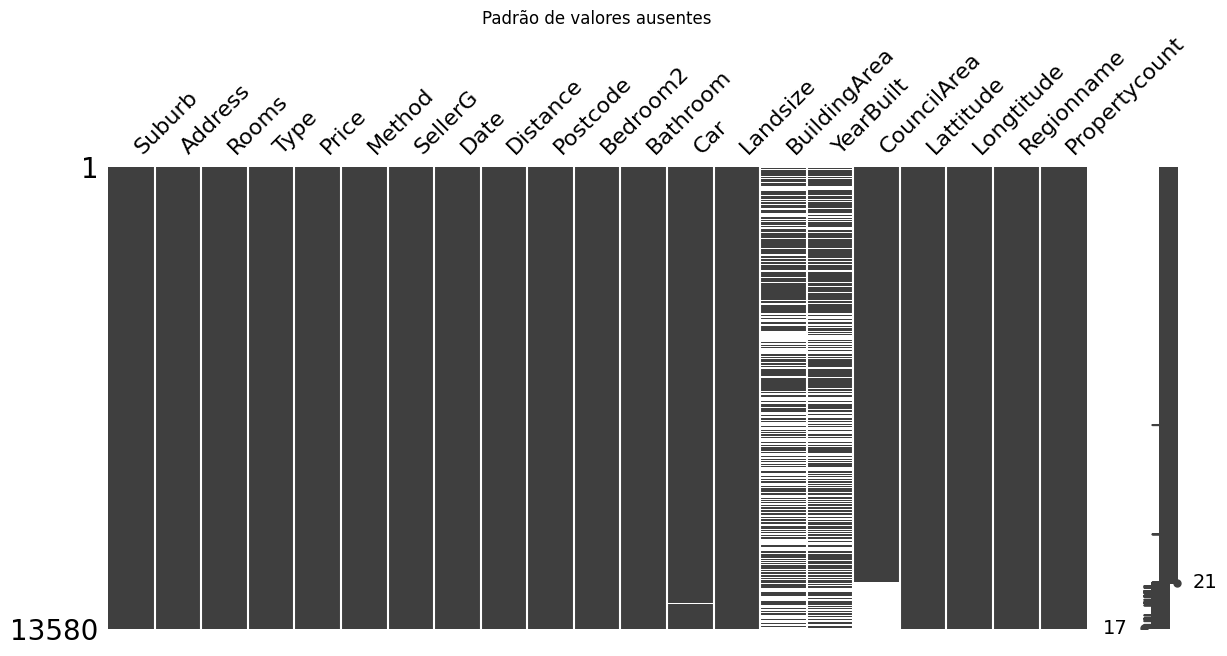

In [ ]:
msno.matrix(dados, figsize=(14, 6))

plt.title('Padrão de valores ausentes')
plt.show()

O gráfico mostra que os valores ausentes estão concentrados principalmente em duas colunas, enquanto a maioria das outras apresenta poucos ou nenhum valor ausente. As faixas brancas indicam os dados faltantes. Além disso, é possível observar que existem ausências nas mesmas linhas, sugerindo que alguns valores podem estar faltando simultaneamente em diferentes colunas.

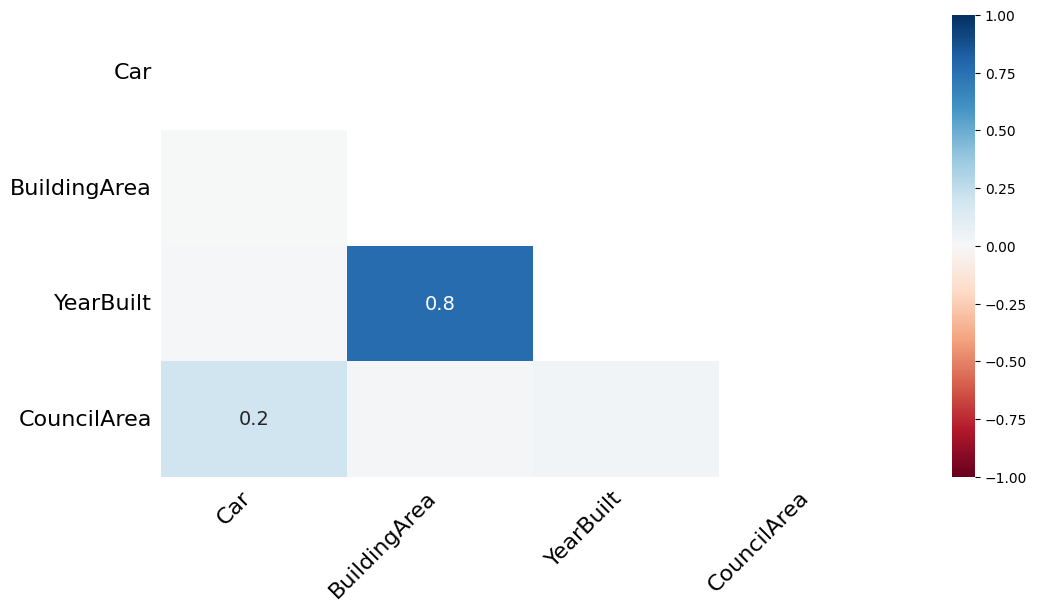

In [ ]:
# Visualizar a relação entre as ausências
msno.heatmap(dados, figsize=(12, 6))
plt.show()

BuildingArea e YearBuilt (0,8): quando falta um desses valores, há uma tendência considerável de o outro também estar ausente.



Car e CouncilArea (0,2): a relação entre as ausências é fraca.




4. Aplique pelo menos duas estratégias de tratamento, guardando cada resultado em um
DataFrame separado (nunca altere o original):

a) remoção (de linhas ou de colunas — decida qual e justifique);

In [ ]:
dados_remocao = dados.copy()

In [ ]:
# Remover colunas com mais de 30% de valores ausentes
limite = 30

porcentagem_ausentes = dados_remocao.isnull().mean() * 100

colunas_remover = porcentagem_ausentes[
    porcentagem_ausentes > limite
].index


In [ ]:
dados_remocao = dados_remocao.drop(columns=colunas_remover)

In [ ]:
print("Colunas removidas:", list(colunas_remover))
print("Dimensões originais:", dados.shape)
print("Dimensões após remoção:", dados_remocao.shape)

Colunas removidas: []
Dimensões originais: (13580, 21)
Dimensões após remoção: (6196, 21)


Escolhi remover as colunas que apresentam mais de 30% de valores ausentes, pois o preenchimento de uma quantidade elevada de dados poderia comprometer a confiabilidade da análise.

b) imputação por uma medida estatística adequada ao tipo da coluna.

In [ ]:
dados_imputacao = dados.copy()

In [ ]:
for coluna in dados_imputacao.columns:

    if dados_imputacao[coluna].isnull().any():

        if pd.api.types.is_numeric_dtype(dados_imputacao[coluna]):
            # Colunas numéricas: mediana
            dados_imputacao[coluna] = dados_imputacao[coluna].fillna(
                dados_imputacao[coluna].median()
            )

        else:
            # Colunas categóricas: moda
            moda = dados_imputacao[coluna].mode()

            if not moda.empty:
                dados_imputacao[coluna] = dados_imputacao[coluna].fillna(
                    moda.iloc[0]
                )

In [ ]:
print("Linhas originais:", len(dados))
print("Linhas após imputação:", len(dados_imputacao))
print("Valores ausentes restantes:", dados_imputacao.isnull().sum().sum())


Linhas originais: 13580
Linhas após imputação: 13580
Valores ausentes restantes: 0


Na estratégia de imputação, foram mantidas as 13.580 linhas originais do dataset. Os valores ausentes foram preenchidos utilizando a mediana nas colunas numéricas e a moda nas colunas categóricas.

5. Compare as estratégias: quantas linhas restaram em cada caso? Como mudaram a média, a
mediana e a distribuição das colunas tratadas?

In [ ]:
print("Quantidade de linhas:")
print("Original:", len(dados))
print("Remoção:", len(dados_remocao))
print("Imputação:", len(dados_imputacao))

Quantidade de linhas:
Original: 13580
Remoção: 6196
Imputação: 13580


In [ ]:
# Comparação das estatísticas das colunas numéricas
print("\nEstatísticas — dados originais:")
display(dados.describe())


Estatísticas — dados originais:


,Rooms,Price,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Lattitude,Longtitude,Propertycount
count,13580.000000,1.358000e+04,13580.000000,13580.000000,13580.000000,13580.000000,13518.000000,13580.000000,7130.000000,8205.000000,13580.000000,13580.000000,13580.000000
mean,2.937997,1.075684e+06,10.137776,3105.301915,2.914728,1.534242,1.610075,558.416127,151.967650,1964.684217,-37.809203,144.995216,7454.417378
std,0.955748,6.393107e+05,5.868725,90.676964,0.965921,0.691712,0.962634,3990.669241,541.014538,37.273762,0.079260,0.103916,4378.581772
min,1.000000,8.500000e+04,0.000000,3000.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1196.000000,-38.182550,144.431810,249.000000
25%,2.000000,6.500000e+05,6.100000,3044.000000,2.000000,1.000000,1.000000,177.000000,93.000000,1940.000000,-37.856822,144.929600,4380.000000
50%,3.000000,9.030000e+05,9.200000,3084.000000,3.000000,1.000000,2.000000,440.000000,126.000000,1970.000000,-37.802355,145.000100,6555.000000
75%,3.000000,1.330000e+06,13.000000,3148.000000,3.000000,2.000000,2.000000,651.000000,174.000000,1999.000000,-37.756400,145.058305,10331.000000
max,10.000000,9.000000e+06,48.100000,3977.000000,20.000000,8.000000,10.000000,433014.000000,44515.000000,2018.000000,-37.408530,145.526350,21650.000000


In [ ]:
print("\nEstatísticas — após remoção:")
display(dados_remocao.describe())


Estatísticas — após remoção:


,Rooms,Price,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Lattitude,Longtitude,Propertycount
count,6196.000000,6.196000e+03,6196.000000,6196.000000,6196.000000,6196.000000,6196.000000,6196.000000,6196.000000,6196.000000,6196.000000,6196.000000,6196.000000
mean,2.931407,1.068828e+06,9.751097,3101.947708,2.902034,1.576340,1.573596,471.006940,141.568645,1964.081988,-37.807904,144.990201,7435.489509
std,0.971079,6.751564e+05,5.612065,86.421604,0.970055,0.711362,0.929947,897.449881,90.834824,38.105673,0.075850,0.099165,4337.698917
min,1.000000,1.310000e+05,0.000000,3000.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1196.000000,-38.164920,144.542370,389.000000
25%,2.000000,6.200000e+05,5.900000,3044.000000,2.000000,1.000000,1.000000,152.000000,91.000000,1940.000000,-37.855438,144.926198,4383.750000
50%,3.000000,8.800000e+05,9.000000,3081.000000,3.000000,1.000000,1.000000,373.000000,124.000000,1970.000000,-37.802250,144.995800,6567.000000
75%,4.000000,1.325000e+06,12.400000,3147.000000,3.000000,2.000000,2.000000,628.000000,170.000000,2000.000000,-37.758200,145.052700,10175.000000
max,8.000000,9.000000e+06,47.400000,3977.000000,9.000000,8.000000,10.000000,37000.000000,3112.000000,2018.000000,-37.457090,145.526350,21650.000000


In [ ]:
print("\nEstatísticas — após imputação:")
display(dados_imputacao.describe())



Estatísticas — após imputação:


,Rooms,Price,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Lattitude,Longtitude,Propertycount
count,13580.000000,1.358000e+04,13580.000000,13580.000000,13580.000000,13580.000000,13580.000000,13580.000000,13580.000000,13580.000000,13580.000000,13580.000000,13580.000000
mean,2.937997,1.075684e+06,10.137776,3105.301915,2.914728,1.534242,1.611856,558.416127,139.633972,1966.788218,-37.809203,144.995216,7454.417378
std,0.955748,6.393107e+05,5.868725,90.676964,0.965921,0.691712,0.960793,3990.669241,392.217403,29.088642,0.079260,0.103916,4378.581772
min,1.000000,8.500000e+04,0.000000,3000.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1196.000000,-38.182550,144.431810,249.000000
25%,2.000000,6.500000e+05,6.100000,3044.000000,2.000000,1.000000,1.000000,177.000000,122.000000,1960.000000,-37.856822,144.929600,4380.000000
50%,3.000000,9.030000e+05,9.200000,3084.000000,3.000000,1.000000,2.000000,440.000000,126.000000,1970.000000,-37.802355,145.000100,6555.000000
75%,3.000000,1.330000e+06,13.000000,3148.000000,3.000000,2.000000,2.000000,651.000000,129.940000,1975.000000,-37.756400,145.058305,10331.000000
max,10.000000,9.000000e+06,48.100000,3977.000000,20.000000,8.000000,10.000000,433014.000000,44515.000000,2018.000000,-37.408530,145.526350,21650.000000


**Remoção**
*   Restaram 6.196 linhas;
*   A média passou de aproximadamente 1.075.684 para 1.068.828;
*   A mediana permaneceu 950.000;
*   Pode alterar a distribuição por excluir muitos registros;
*   Reduziu significativamente o tamanho do data base;
---
**Imputação**
*   Foram mantidas as 13.580 linhas originais;
*   A média e a mediana permaneceram iguais;
*   Pode reduzir potencialmente a variabilidade;
*   Preservou mais informações;



**Para refletir**

* Uma coluna com mais da metade dos valores ausentes deve ser imputada ou descartada? De que essa decisão depende?

É sempre melhor preencher os dados ausentes, porém, depende da importância da coluna para a análise. Se ela for relevante, pode ser mantida e ter seus valores imputados. Se tiver pouca utilidade, pode ser descartada.


* Para colunas como Price ou Landsize, média e mediana dariam valores de imputação parecidos? Qual seria mais segura, e por quê?


Não necessariamente. A média é influenciada por valores extremos, enquanto a mediana é mais resistente a eles. Por isso, a mediana costuma ser mais segura para essas colunas.


3. Em que situação o fato de um valor estar ausente é, por si só, uma informação útil para a análise?

Quando a ausência pode indicar alguma característica relevante do imóvel ou do processo de coleta dos dados.

**Desafio**

In [33]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

In [35]:
# Selecionar colunas numéricas relacionadas aos imóveis
colunas = [
    'Rooms', 'Distance', 'Bedroom2', 'Bathroom',
    'Car', 'Landsize', 'BuildingArea', 'YearBuilt', 'Price'
]

dados_knn = dados[colunas].copy()

In [34]:
# Padronizar as escalas para que valores grandes não dominem as distâncias
escalador = StandardScaler()
dados_escalados = escalador.fit_transform(dados_knn)

In [ ]:
# Padronizar as escalas para que valores grandes não dominem as distâncias
escalador = StandardScaler()
dados_escalados = escalador.fit_transform(dados_knn)

In [36]:
# Imputar usando os 5 vizinhos mais próximos
imputador = KNNImputer(n_neighbors=5)
dados_preenchidos = imputador.fit_transform(dados_escalados)

In [37]:
# Voltar à escala original
dados_knn[colunas] = escalador.inverse_transform(dados_preenchidos)

In [39]:
# Comparar BuildingArea com a imputação pela mediana
mediana = dados['BuildingArea'].median()
faltantes = dados['BuildingArea'].isnull()

In [40]:
print("Valores ausentes originais:", faltantes.sum())
print("Mediana usada:", mediana)
print("Média dos valores imputados pela mediana:",
      dados.loc[faltantes, 'BuildingArea'].fillna(mediana).mean())
print("Média dos valores imputados pelo KNN:",
      dados_knn.loc[faltantes, 'BuildingArea'].mean())
print("\nEstatísticas de BuildingArea:")
comparacao = pd.DataFrame({
    'Original': dados['BuildingArea'].describe(),
    'Mediana': dados['BuildingArea'].fillna(mediana).describe(),
    'KNNImputer': dados_knn['BuildingArea'].describe()
})

Valores ausentes originais: 6450
Mediana usada: 126.0
Média dos valores imputados pela mediana: 126.0
Média dos valores imputados pelo KNN: 147.4329721488372

Estatísticas de BuildingArea:


In [41]:
display(comparacao.round(2))

,Original,Mediana,KNNImputer
count,7130.00,13580.00,13580.00
mean,151.97,139.63,149.81
std,541.01,392.22,430.51
min,0.00,0.00,0.00
25%,93.00,122.00,95.00
50%,126.00,126.00,125.20
75%,174.00,129.94,170.65
max,44515.00,44515.00,44515.00


In [42]:
print("Ausentes após KNN:", dados_knn.isnull().sum().sum())

Ausentes após KNN: 0


O KNN usa os cinco vizinhos mais próximos para estimar os valores ausentes.

* Imputação estatística: preenche todos os valores ausentes de BuildingArea com a mesma mediana.

 * KNNImputer: pode preencher cada imóvel com um valor diferente, considerando as características de imóveis semelhantes.

* Custo: o KNN exige mais processamento e memória, além de depender da escolha das variáveis, do número de vizinhos e da escala dos dados. Também não garante estimativas mais precisas em todos os casos.

Enquanto a mediana preenche todos os valores ausentes de BuildingArea com 126, o KNN estima valores com base nas características de imóveis semelhantes, preservando maior variação nos dados. A média final foi de 149,81 com o KNN e 139,63 com a mediana. Ambos os métodos eliminaram os valores ausentes sem remover linhas. Entretanto, o KNN exige mais processamento e depende da escolha das variáveis e dos vizinhos utilizados, não garantindo necessariamente maior precisão.